In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/projects/active_operator_learning
!git config user.name "ethannaegele"
!git config user.email "enaegele500@gmail.com"

/content/drive/MyDrive/projects/active_operator_learning


In [ ]:
!nvidia-smi

Fri Jun  5 21:20:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# install micromamba
%%bash
set -e

cd /content

if [ ! -f /usr/local/bin/micromamba ]; then
  curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xvj bin/micromamba
  chmod +x bin/micromamba
  mv bin/micromamba /usr/local/bin/micromamba
fi

micromamba --version

bin/micromamba
2.8.0


In [4]:
%%bash
set -e

export MAMBA_ROOT_PREFIX=/content/micromamba

micromamba create -y -n al-env-gpu -c conda-forge \
  python=3.10 \
  pip \
  numpy=1.26.4 \
  pandas \
  scipy \
  scikit-learn \
  scikit-image \
  matplotlib \
  h5py \
  imageio \
  pillow \
  tqdm \
  pyyaml \
  requests \
  networkx \
  ipython \
  ipykernel

Fetch Shard Index for conda-forge/linux-64                                                      ⧖ Starting
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.1 sec)
Fetch Shard Index for conda-forge/noarch                                                        ⧖ Starting
Fetch Shard Index for conda-forge/noarch                                                  ✔ Done (0.1 sec)
Fetching and Parsing Packages' Shards                                                           ⧖ Starting
Fetching and Parsing Packages' Shards                                                    ✔ Done (26.2 sec)

Resolving Environment                                                                           ⧖ Starting
Resolving Environment                                                                     ✔ Done (0.7 sec)

Transaction

  Prefix: /content/micromamba/envs/al-env-gpu

  Updating specs:

   - python=3.10
   - pip
   - numpy=1.26.4
   - pandas
   - sc

In [5]:
%%bash
set -e

export MAMBA_ROOT_PREFIX=/content/micromamba

micromamba run -n al-env-gpu python -m pip install --upgrade pip setuptools wheel

micromamba run -n al-env-gpu python -m pip install \
  torch==2.2.2+cu121 \
  torchvision==0.17.2+cu121 \
  torchaudio==2.2.2+cu121 \
  --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 757.3/757.3 MB 30.2 MB/s  0:00:13
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 132.6 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 95.5 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 132.8 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 42.3 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 137.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 23.5 MB/s  0:00:16
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 55.5 MB/s  0:00:05
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 63.6 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 66.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 67.3 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 65.9 MB/s  

In [6]:
%%bash
set -e

export MAMBA_ROOT_PREFIX=/content/micromamba

micromamba run -n al-env-gpu python -m pip install \
  absl-py \
  annotated-types \
  antlr4-python3-runtime==4.9.3 \
  anyio \
  attrs \
  bmdal-reg \
  chex==0.1.86 \
  click \
  cliffordlayers \
  cloudpickle \
  cyclopts \
  diffusers==0.17.1 \
  dm-haiku==0.0.12 \
  docstring-parser \
  einops \
  etils \
  fdtd \
  filelock \
  flax==0.8.2 \
  fsspec \
  gitpython \
  grpcio \
  h11 \
  httpcore \
  httpx \
  humanize \
  hydra-core==1.3.2 \
  hydra-submitit-launcher==1.2.0 \
  importlib-metadata \
  importlib-resources \
  iniconfig \
  jax==0.4.38 \
  jaxlib==0.4.38 \
  jax-cfd==0.2.0 \
  jinja2 \
  jmp \
  jsonargparse \
  juliapkg \
  liac-arff \
  lightning==2.2.1 \
  lightning-utilities \
  markdown \
  markdown-it-py \
  markupsafe \
  mat4py \
  minio \
  ml-dtypes \
  mpmath \
  msgpack \
  omegaconf \
  openml \
  opt-einsum \
  optax==0.2.2 \
  orbax-checkpoint \
  orjson \
  packaging \
  phiflow==2.1.0 \
  phiml \
  pluggy \
  pooch \
  pycryptodome \
  pydantic \
  pytest \
  pytest-explicit \
  pytest-mock \
  pytorch-lightning \
  pyvers \
  pyvista \
  rich \
  rich-rst \
  scooby \
  seaborn \
  semver \
  sentry-sdk \
  simplejson \
  submitit \
  sympy \
  tabulate \
  tensorboard \
  tensordict \
  tensorstore \
  tomli \
  tomlkit \
  toolz \
  torchdata \
  torchmetrics \
  tree-math \
  typing-inspection \
  vtk \
  wandb \
  werkzeug \
  xarray \
  xmltodict \
  zipp

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installi

In [7]:
# install local packages: pdearena and al4pde
%%bash
set -e

export MAMBA_ROOT_PREFIX=/content/micromamba
cd /content/drive/MyDrive/projects/active_operator_learning

micromamba run -n al-env-gpu python -m pip install -e "./external/pdearena[datagen]"
micromamba run -n al-env-gpu python -m pip install -e .

Obtaining file:///content/drive/MyDrive/projects/active_operator_learning/external/pdearena
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for pdearena (pyproject.toml): started
  Building editable for pdearena (pyproject.toml): finished with status 'done'
  Created wheel for pdearena: filename=pdearena-0.2.0-0.editable-py3-none-any.whl size=5931 sha256=220e745bd02024cdcaf274f1571f615080dde157f9cfd353e5af5f0336b64ecf
  Stored in directory: /tmp/pip-ephem-wheel-cache-n2p9rbm9/wheels/56/1b/9a/42a12c7b4f1b0b6ea7766560f35cdef1ee8

In [8]:
%%bash
set -e

export MAMBA_ROOT_PREFIX=/content/micromamba

micromamba run -n al-env-gpu python - <<'PY'
import sys
print("Python:", sys.version)

import numpy as np
print("NumPy:", np.__version__)

import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Torch CUDA:", torch.version.cuda)

import jax
print("JAX:", jax.__version__)
print("JAX devices:", jax.devices())
PY

Python: 3.10.20 | packaged by conda-forge | (main, Mar  5 2026, 16:42:22) [GCC 14.3.0]
NumPy: 1.26.4
Torch: 2.2.2+cu121
CUDA available: True
GPU: Tesla T4
Torch CUDA: 12.1
JAX: 0.4.38
JAX devices: [CpuDevice(id=0)]


In [9]:
# run this cell to avoid having to put the micromamba run -n al-env-gpu python ... every time,
# instead just start each cell with %%alenv
from IPython.core.magic import register_cell_magic
import subprocess
import os
import tempfile

@register_cell_magic
def alenv(line, cell):
    env = os.environ.copy()
    env["MAMBA_ROOT_PREFIX"] = "/content/micromamba"

    debug = "-x" in line.split()

    with tempfile.NamedTemporaryFile("w", suffix=".py", delete=False) as f:
        f.write(cell)
        path = f.name

    cmd = [
        "micromamba", "run", "-n", "al-env-gpu",
        "python", path
    ]

    print("Running Python inside Micromamba env: al-env-gpu")
    print("Python file:", path)
    if debug:
        print("Command:")
        print(" ".join(cmd))
        print("-" * 80)

    result = subprocess.run(
        cmd,
        env=env,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
    )

    if result.stdout:
        print("STDOUT:")
        print(result.stdout)

    if result.stderr:
        print("STDERR:")
        print(result.stderr)

    if result.returncode != 0:
        print(f"\nExited with code {result.returncode}")

# cell magic for shell commands


@register_cell_magic
def alenvsh(line, cell):
    env = os.environ.copy()
    env["MAMBA_ROOT_PREFIX"] = "/content/micromamba"

    # Optional: allow args after %%alenvsh, e.g. %%alenvsh -x
    shell_prefix = "set -e\n"
    if "-x" in line.split():
        shell_prefix = "set -ex\n"

    script = shell_prefix + cell

    print("Running inside Micromamba env: al-env-gpu")
    print("Command:")
    print(script)
    print("-" * 80)

    result = subprocess.run(
        ["micromamba", "run", "-n", "al-env-gpu", "bash", "-lc", script],
        env=env,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
    )

    if result.stdout:
        print("STDOUT:")
        print(result.stdout)

    if result.stderr:
        print("STDERR:")
        print(result.stderr)

    if result.returncode != 0:
        raise RuntimeError(
            f"al-env-gpu shell cell failed with exit code {result.returncode}"
        )

In [10]:
%%alenv
import sys
import torch

print(sys.executable)
print(torch.__version__)
print(torch.cuda.is_available())

Running Python inside Micromamba env: al-env-gpu
Python file: /tmp/tmp4tdacqcw.py
STDOUT:
/content/micromamba/envs/al-env-gpu/bin/python
2.2.2+cu121
True



In [ ]:
%cd /content/drive/MyDrive/projects/active_operator_learning

/content/drive/MyDrive/projects/active_operator_learning


In [ ]:
import wandb
wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: enaegele500 (enaegele500-none) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [ ]:
import os
os.environ["HYDRA_FULL_ERROR"] = "1"

In [ ]:
%%alenvsh
python -m scripts.al_submitit --m \
  +experiment=ks \
  acquisition/data_schedule=linear \
  prob_model/model_wrapper=fno \
  prob_model.unc_roll_out_mode="independent" \
  acquisition.batch_size=32 \
  num_epochs=2 \
  num_al_iter=2 \
  prob_model.model_wrapper.batch_size=1024 \
  hydra=base

Running inside Micromamba env: al-env-gpu
Command:
set -e
python -m scripts.al_submitit --m \
  +experiment=ks \
  acquisition/data_schedule=linear \
  prob_model/model_wrapper=fno \
  prob_model.unc_roll_out_mode="independent" \
  acquisition.batch_size=32 \
  num_epochs=2 \
  num_al_iter=2 \
  prob_model.model_wrapper.batch_size=1024 \
  hydra=base

--------------------------------------------------------------------------------
STDOUT:
CFG is: {'wandb': {'group': 'ks', 'name': None, 'project': 'al4pde'}, 'seed': 0, 'num_epochs': 2, 'start_al_iter': 0, 'num_al_iter': 2, 'restore_checkpoint': False, 'checkpoint_file_name': 'latest.pt', 'checkpoint_id': 'c1papzmi', 'acquisition': {'data_schedule': {'_target_': 'al4pde.acquisition.data_schedule.LinearSchedule', 'first_batch_num': '${task.data_gen.num_initial_batches}'}, 'batch_size': 32, 'unc_num_rollout_steps_rel': 1.0, 'unc_eval_mode': 'mean', '_target_': 'al4pde.acquisition.random.Random'}, 'task': {'_target_': 'al4pde.tasks.task.Tas

In [ ]:
%%alenv


Running Python inside Micromamba env: al-env-gpu
Python file: /tmp/tmpvysx1zvj.py
STDERR:
Traceback (most recent call last):
  File "/tmp/tmpvysx1zvj.py", line 13, in <module>
    cfg = hydra.compose(
  File "/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/hydra/compose.py", line 38, in compose
    cfg = gh.hydra.compose_config(
  File "/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/hydra/_internal/hydra.py", line 594, in compose_config
    cfg = self.config_loader.load_configuration(
  File "/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/hydra/_internal/config_loader_impl.py", line 142, in load_configuration
    return self._load_configuration_impl(
  File "/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/hydra/_internal/config_loader_impl.py", line 243, in _load_configuration_impl
    self.ensure_main_config_source_available()
  File "/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/hydra/_internal/c

In [22]:
%%bash
export MAMBA_ROOT_PREFIX=/content/micromamba

micromamba run -n al-env-gpu python - <<'PY'
import os
import torch
import hydra
from omegaconf import OmegaConf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


from al4pde.prob_models.build_prob_model import build_prob_model
from al4pde.utils import load_checkpoint
from al4pde.models.dataloader import NPYDataset

os.chdir("/content/drive/MyDrive/projects/active_operator_learning")

# You need the same config used for training.
with hydra.initialize(version_base="1.3.2", config_path="config"):
    cfg = hydra.compose(
        config_name="main",
        overrides=[
            "+experiment=ks",
            "acquisition/data_schedule=linear",
            "prob_model/model_wrapper=fno",
            "prob_model.unc_roll_out_mode=independent",
            "acquisition.batch_size=32",
            "num_epochs=2",
            "num_al_iter=2",
            "prob_model.model_wrapper.batch_size=1024",
            "hydra=base"
        ],
    )

run_id = "pc0usg90"
checkpoint_name = "1.pt"

run_save_path = os.path.join(cfg.task.run_save_path, run_id)

task = hydra.utils.instantiate(cfg.task, run_save_path=run_save_path)
prob_model = build_prob_model(task, cfg.prob_model)

al_iter, sampling_finished = load_checkpoint(
    run_save_path,
    checkpoint_name,
    prob_model,
    train=False,
    load_train_data=True,
)

#prob_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# This should point to the test set folder, not an individual file.
test_folder = "data/data/KS/test"

test_data = NPYDataset(
    pde_name=task.pde_name,                         # "KS"
    folders=[test_folder],
    reduced_resolution=prob_model.reduced_resolution,
    reduced_resolution_t=prob_model.reduced_resolution_t,
    reduced_batch=prob_model.reduced_batch,
    initial_step=prob_model.initial_step,
    skip_initial_steps=prob_model.skip_initial_steps,
    save_in_reduced_res=task.save_in_reduced_res,
).set_num_steps(None)

# Pick one example. Dataset indexing returns:
# xx: initial condition window
# yy: full trajectory segment
# grid: spatial grid
# pde_param: PDE parameter
# t_idx: starting time index
sample_idx = 0
xx, yy, grid, pde_param, t_idx = test_data[sample_idx]

# Add batch dimension and move to device.
xx = xx.unsqueeze(0).to(device)              # [1, x, initial_step, channels]
yy = yy.unsqueeze(0).to(device)              # [1, x, time, channels]
grid = grid.unsqueeze(0).to(device)          # [1, x, spatial_dim]
pde_param = pde_param.unsqueeze(0).to(device) # [1, num_pde_params]
t_idx = t_idx.unsqueeze(0).to(device)         # [1]

prob_model.eval()

with torch.no_grad():
    # yy.shape[-2] is the trajectory length in time.
    pred = prob_model.roll_out(
        xx=xx,
        grid=grid,
        final_step=yy.shape[-2],
        pde_param=pde_param,
        t_idx=t_idx,
    )

print("xx shape:", xx.shape)
print("yy shape:", yy.shape)
print("pred shape:", pred.shape)
print("pde_param:", pde_param)

rmse = torch.sqrt(torch.mean((pred - yy) ** 2)).item()
rel_l2 = (
    torch.linalg.norm((pred - yy).reshape(1, -1), dim=1)
    / torch.linalg.norm(yy.reshape(1, -1), dim=1)
).item()

print("RMSE:", rmse)
print("Relative L2:", rel_l2)
print(device)

out_dir = "/content/drive/MyDrive/projects/active_operator_learning/plots/KS_plots/KS_random_acquisition_trial_run_plots"
os.makedirs(out_dir, exist_ok=True)


true_np = yy[0, ..., 0].detach().cpu().numpy()
pred_np = pred[0, ..., 0].detach().cpu().numpy()
err_np = abs(pred_np - true_np)

plt.figure(figsize=(6, 4))
plt.imshow(true_np.T, aspect="auto", origin="lower")
plt.title("True KS trajectory")
plt.xlabel("x index")
plt.ylabel("time index")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{out_dir}/true_ks.png", dpi=200)
plt.close()

plt.figure(figsize=(6, 4))
plt.imshow(pred_np.T, aspect="auto", origin="lower")
plt.title("Predicted KS trajectory")
plt.xlabel("x index")
plt.ylabel("time index")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{out_dir}/pred_ks.png", dpi=200)
plt.close()

plt.figure(figsize=(6, 4))
plt.imshow(err_np.T, aspect="auto", origin="lower")
plt.title("Absolute error")
plt.xlabel("x index")
plt.ylabel("time index")
plt.colorbar()
plt.tight_layout()
plt.savefig(f"{out_dir}/err_ks.png", dpi=200)
plt.close()

print("Saved plots to:", out_dir)


PY

using val, loading data/data/KS/val
init training
MODEL: Building FNO1D
Total parameters = 353154
number of trajectories in data: 512
number of trajectories in data: 256
std channels Parameter containing:
tensor([1.1401])
std grid Parameter containing:
tensor([0.2898])
std params Parameter containing:
tensor([0.2733])
restored checkpoint 1.pt from active learning iteration 1 .Sampling finished:  False
number of trajectories in data: 256
xx shape: torch.Size([1, 256, 1, 1])
yy shape: torch.Size([1, 256, 41, 1])
pred shape: torch.Size([1, 256, 41, 1])
pde_param: tensor([[0.6876]], device='cuda:0')
RMSE: 3.8824262619018555
Relative L2: 3.089672803878784
cuda
Saved plots to: /content/drive/MyDrive/projects/active_operator_learning/plots/KS_plots/KS_random_acquisition_trial_run_plots


/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/tensordict/_pytree.py:218: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  register_pytree_node(
/content/micromamba/envs/al-env-gpu/lib/python3.10/site-packages/tensordict/_pytree.py:237: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  register_pytree_node(


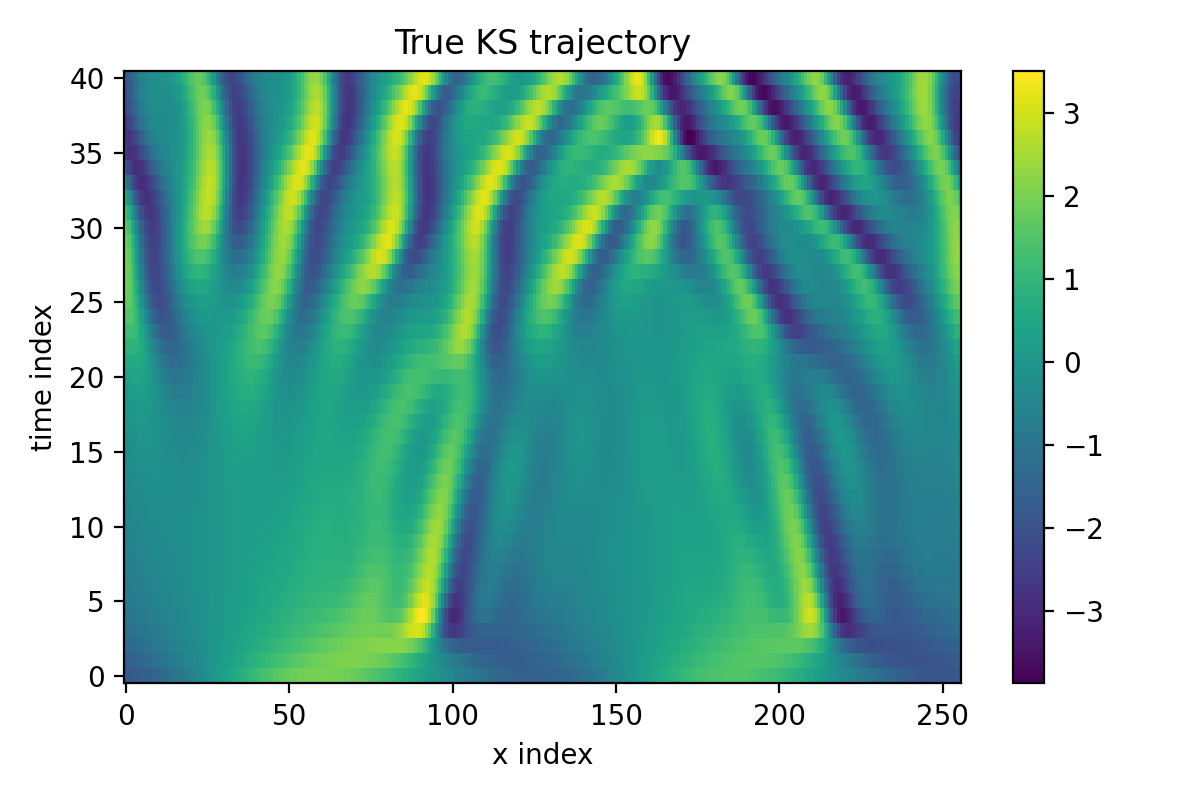

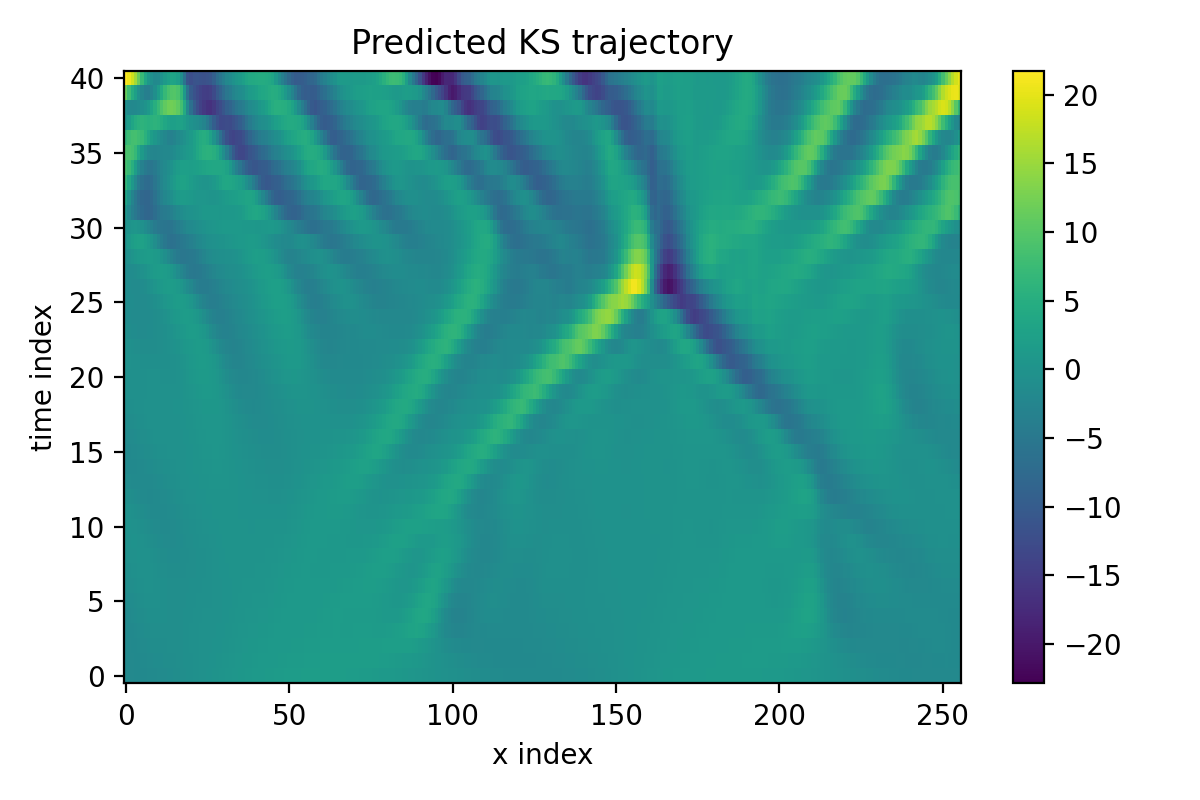

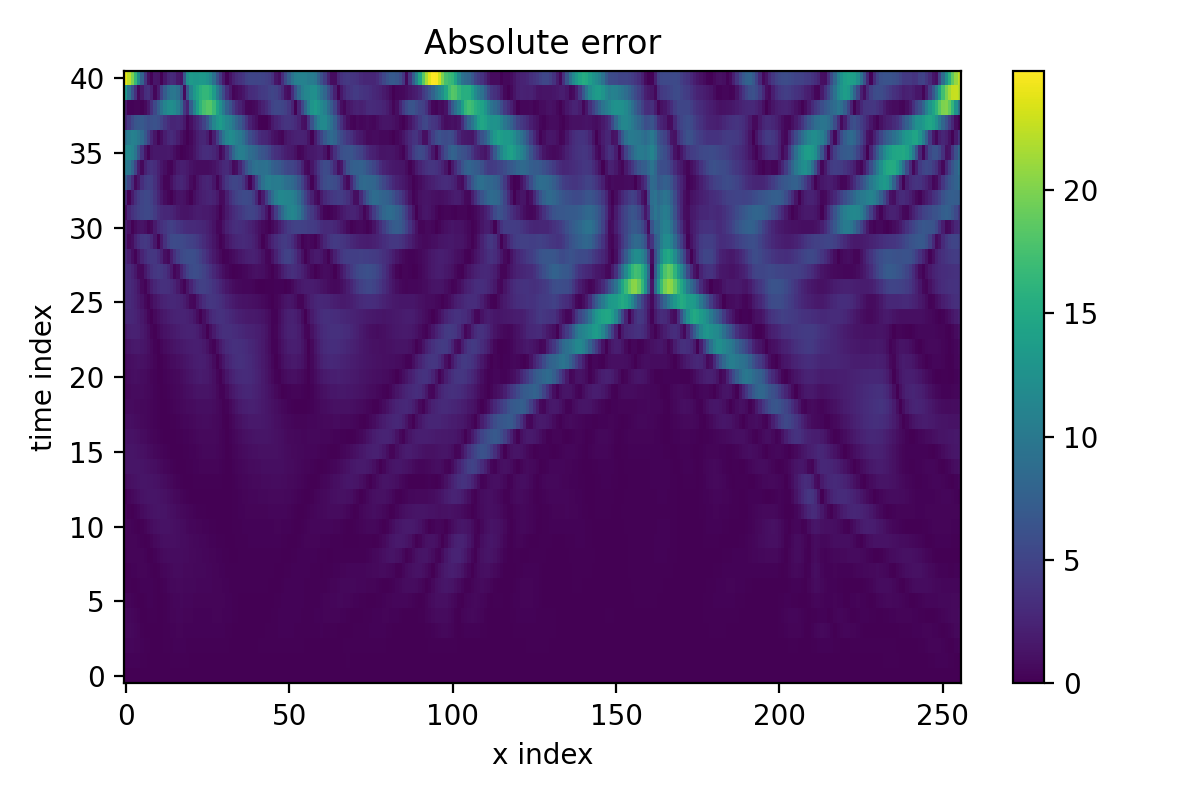

In [23]:
from IPython.display import Image, display

path = "/content/drive/MyDrive/projects/active_operator_learning/plots/KS_plots/KS_random_acquisition_trial_run_plots"
display(Image(f"{path}/true_ks.png"))
display(Image(f"{path}/pred_ks.png"))
display(Image(f"{path}/err_ks.png"))

In [24]:

!git add ks_small_random_acquisition_trial_run.ipynb ks_small_datagen.ipynb plots/
!git commit -m "Added notebook including AL random acq trial run for KS + loaded model + evaluated results + added plots"
!git push

fatal: pathspec 'ks_small_random_acquisition_trial_run.ipynb' did not match any files
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   ../../../../burgers_datagen.ipynb
	modified:   ../../../../colab_github_setup.ipynb
	modified:   ../../../../external/pdearena/pdedatagen/scripts/maxwell_jobs.sh
	modified:   ../../../../external/pdearena/pdedatagen/scripts/navierstokes_cond_jobs.sh
	modified:   ../../../../external/pdearena/pdedatagen/scripts/navierstokes_jobs.sh
	modified:   ../../../../external/pdearena/pdedatagen/scripts/shallowwater_jobs.sh
	modified:   ../../../../ks_small_datagen.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	../../../../plots/

no changes added to commit (use "git add" and/or "git commit -a")
Everything up-to-date
